In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import plotly.express as px
from sklearn.preprocessing import LabelEncoder, StandardScaler,MultiLabelBinarizer
from sklearn.cluster import KMeans
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.decomposition import PCA

In [13]:
df = pd.read_csv("cleaned_data.csv")

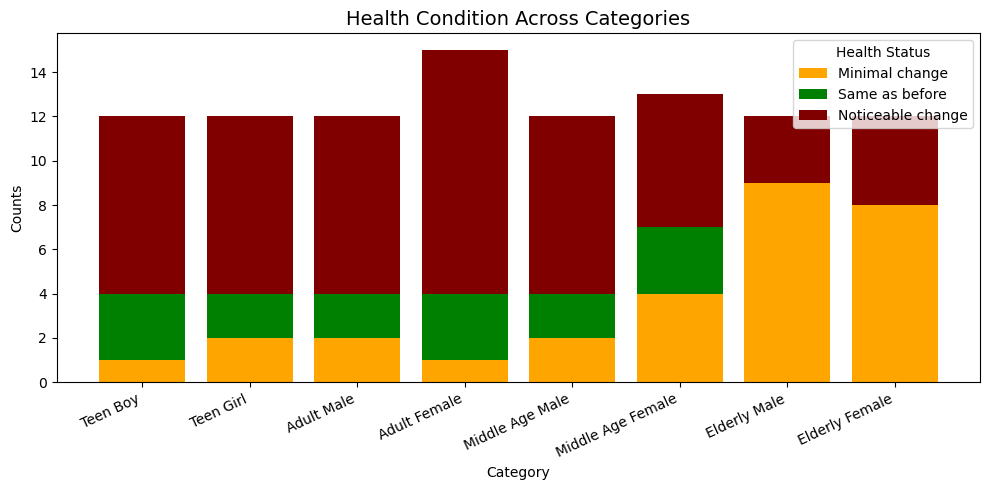

In [22]:
import matplotlib.pyplot as plt
import pandas as pd

target_col = 'Compared to pre-COVID, your overall health condition is'

category_order = [
    'Teen Boy', 'Teen Girl',
    'Adult Male', 'Adult Female',
    'Middle Age Male', 'Middle Age Female',
    'Elderly Male', 'Elderly Female'
]

colors = {
    'Minimal change': 'orange',
    'Same as before': 'green',
    'Noticeable change': 'maroon'
}

# Aggregate counts
ct = pd.crosstab(df['Category'], df[target_col]).reindex(category_order)

fig, ax = plt.subplots(figsize=(10, 5))
bottom = None

# Build stacked bars column by column
for status in ['Minimal change', 'Same as before', 'Noticeable change']:
    if status in ct.columns:
        values = ct[status].values
        if bottom is None:
            ax.bar(ct.index, values, label=status, color=colors[status])
            bottom = values
        else:
            ax.bar(ct.index, values, bottom=bottom, label=status, color=colors[status])
            bottom += values

ax.set_title("Health Condition Across Categories", fontsize=14)
ax.set_xlabel("Category")
ax.set_ylabel("Counts")
plt.xticks(rotation=25, ha='right')
ax.legend(title="Health Status")

plt.tight_layout()
plt.show()

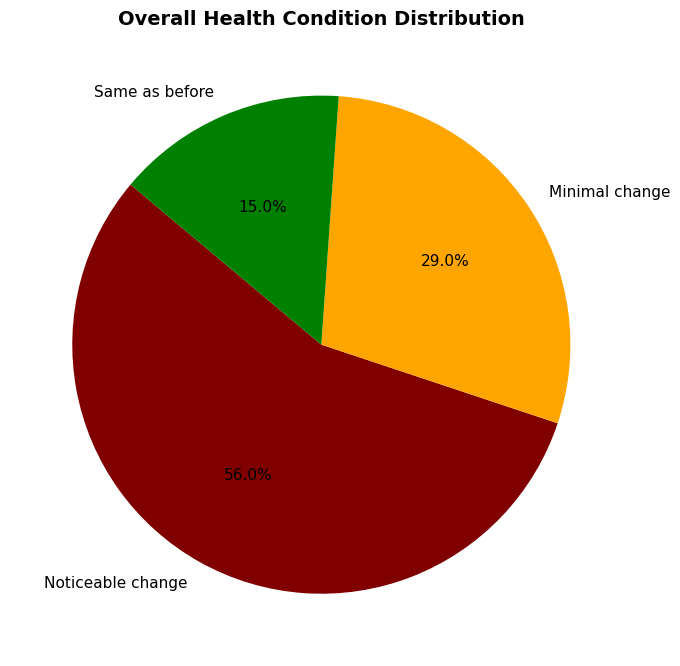

C:\Users\joshi\AppData\Local\Temp\ipykernel_37808\107882045.py:31: UserWarning:

FigureCanvasAgg is non-interactive, and thus cannot be shown



In [23]:
import matplotlib.pyplot as plt

target_col = 'Compared to pre-COVID, your overall health condition is'

color_map = {
    'Minimal change': 'orange',
    'Same as before': 'green',
    'Noticeable change': 'maroon'
}

# 1. Count occurrences for each response
counts = df[target_col].value_counts()

# 2. Map colors in the exact order of the counts series
pie_colors = [color_map[category] for category in counts.index]

# 3. Build pie chart
plt.figure(figsize=(7, 7))
plt.pie(
    counts,
    labels=counts.index,
    colors=pie_colors,
    autopct='%1.1f%%',
    startangle=140,
    textprops={'fontsize': 11}
)

plt.title("Overall Health Condition Distribution", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()
fig.show()

In [16]:
#DESCRIPTIVE STATISTICS (Central Tendencies)
df['Stress level'] = pd.to_numeric(df['Stress level'], errors='coerce')

print("Mean Stress:", df['Stress level'].mean())
print("Median Stress:", df['Stress level'].median())
print("Mode Stress:", df['Stress level'].mode())

Mean Stress: 1.0
Median Stress: 1.0
Mode Stress: 0    1
Name: Stress level, dtype: int64


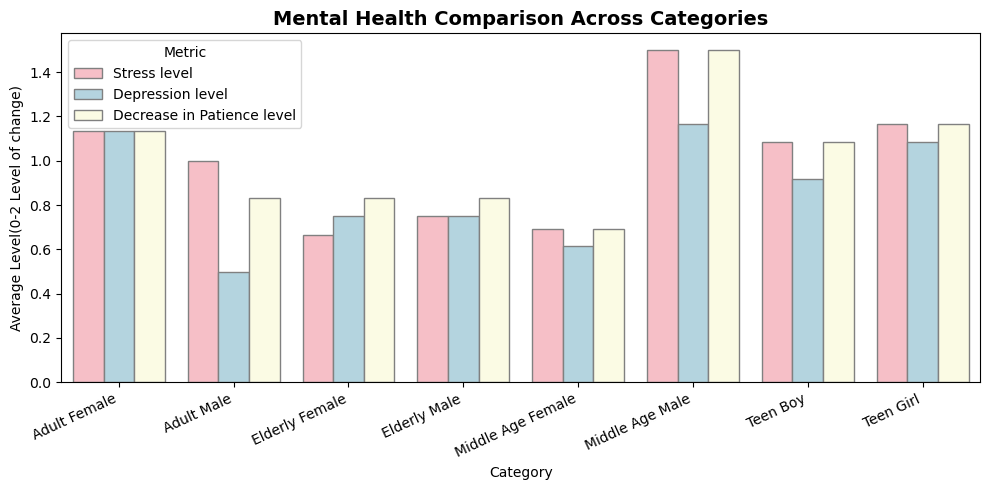

In [24]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Clean up column names and fix double spacing if present
df['Stress level'] = pd.to_numeric(df['Stress level'], errors='coerce')
df['Depression level'] = pd.to_numeric(df['Depression  level'], errors='coerce')
df['Decrease in Patience level'] = pd.to_numeric(df['Decrease in Patience level'], errors='coerce')

# 2. Group and melt data
mental = df.groupby('Category')[['Stress level', 'Depression level', 'Decrease in Patience level']].mean().reset_index()
mental_melt = mental.melt(id_vars='Category', var_name='Metric', value_name='Value')

# 3. Define color mapping
color_map = {
    'Stress level': 'lightpink',
    'Depression level': 'lightblue',
    'Decrease in Patience level': 'lightyellow'
}

# 4. Plot grouped bar chart
plt.figure(figsize=(10, 5))
sns.barplot(
    data=mental_melt, 
    x='Category', 
    y='Value', 
    hue='Metric', 
    palette=color_map,
    edgecolor='gray'
)

# 5. Customize layout
plt.title("Mental Health Comparison Across Categories", fontsize=14, fontweight='bold')
plt.xlabel("Category")
plt.ylabel("Average Level(0-2 Level of change)")
plt.xticks(rotation=25, ha='right')
plt.legend(title="Metric")

plt.tight_layout()
plt.show()

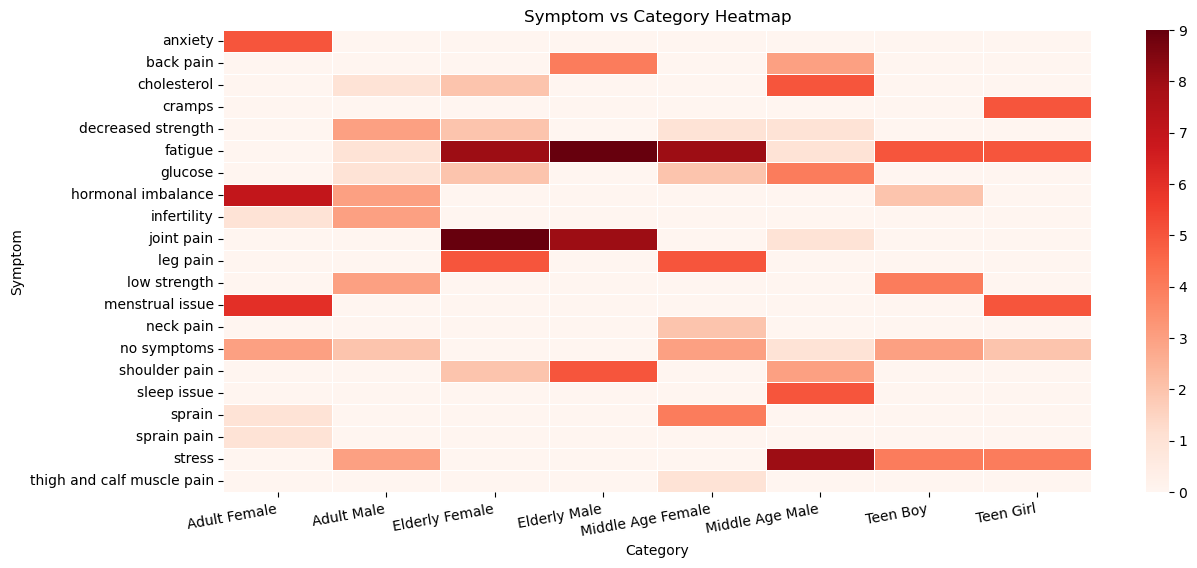

In [19]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import ast

data = []

for _, row in df.iterrows():
    cat = row['Category']
    
    s_list = row['Symptoms_processed']
    
    if isinstance(s_list, str):
        s_list = ast.literal_eval(s_list)
    
    for s in s_list:
        data.append([cat, s])

df_temp = pd.DataFrame(data, columns=['Category', 'Symptom'])

pivot = pd.crosstab(df_temp['Category'], df_temp['Symptom'])

plt.figure(figsize=(14,6))

sns.heatmap(pivot.T, cmap="Reds", linewidths=0.5) 
plt.xticks(rotation=10, ha='right')  

plt.title("Symptom vs Category Heatmap")
plt.show()

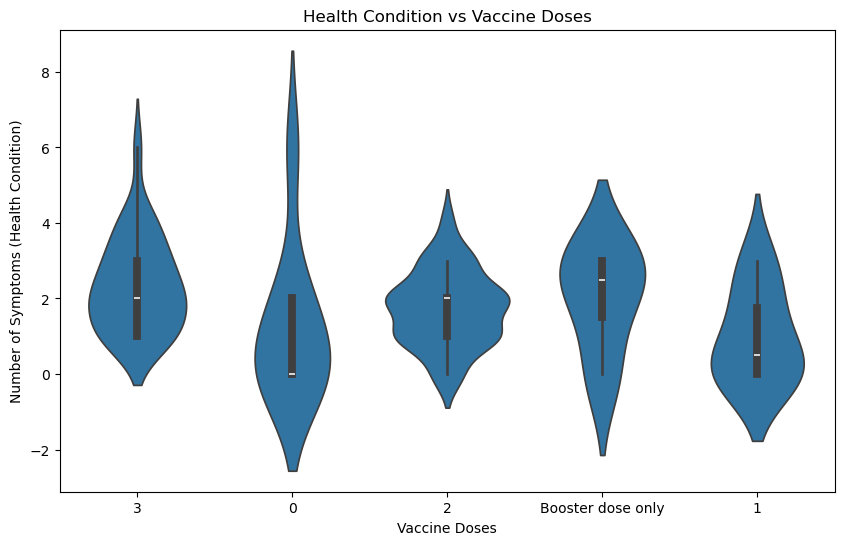

In [20]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import ast

df.columns = df.columns.str.strip()

# List format
df["Symptoms_processed"] = df["Symptoms_processed"].apply(
    lambda x: ast.literal_eval(x) if isinstance(x, str) else x
)

# symptom count 
df["symptom_count"] = df["Symptoms_processed"].apply(
    lambda x: 0 if "no symptoms" in x else len(x)
)

plt.figure(figsize=(10,6))

sns.violinplot(
    x="Number of vaccine doses received",
    y="symptom_count",
    data=df,
    inner="box"
)

plt.xlabel("Vaccine Doses")
plt.ylabel("Number of Symptoms (Health Condition)")
plt.title("Health Condition vs Vaccine Doses")

plt.show()

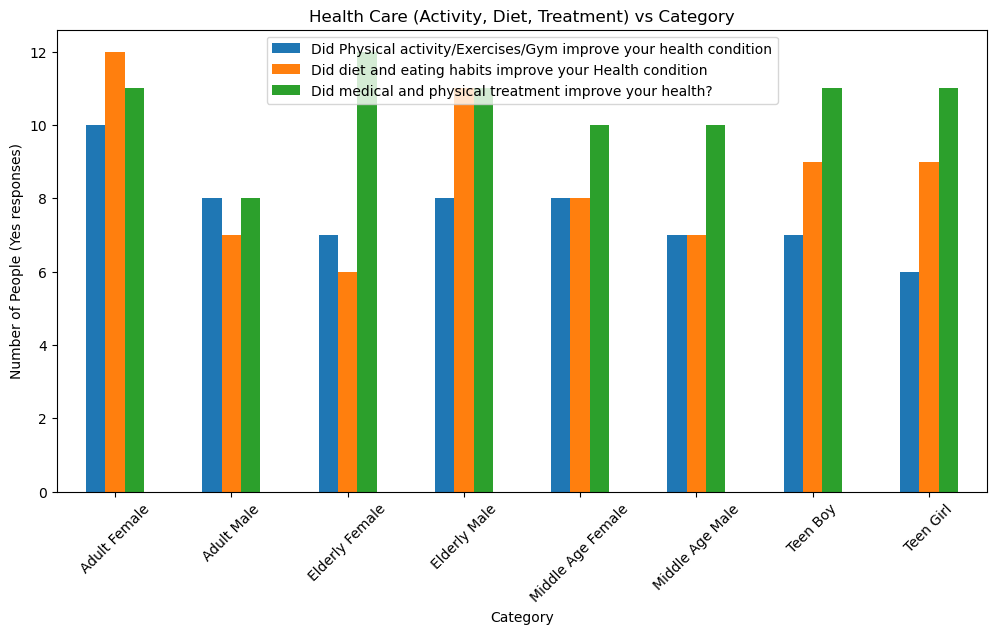

In [21]:
import pandas as pd
import matplotlib.pyplot as plt

df.columns = df.columns.str.strip()

cols = [
    "Did Physical activity/Exercises/Gym improve your health condition",
    "Did diet and eating habits improve your Health condition",
    "Did medical and physical treatment improve your health?"
]

pivot = df.groupby("Category")[cols].apply(lambda x: x.apply(lambda y: (y == "Yes").sum()))

pivot.plot(kind="bar", figsize=(12,6))

plt.xlabel("Category")
plt.ylabel("Number of People (Yes responses)")
plt.title("Health Care (Activity, Diet, Treatment) vs Category")
plt.xticks(rotation=45)

plt.show()